In [13]:
!pip install ucimlrepo

## Sobre a base de dados

Medições do consumo de energia elétrica em uma residência com uma taxa de amostragem de minuto a minuto ao longo de um período de quase 4 anos. Diferentes grandezas elétricas e alguns valores de sub-medição estão disponíveis.

Este notebook explora um conjunto de dados de consumo de energia de uma casa na França, coletado entre dezembro de 2006 e novembro de 2010. O arquivo contém mais de 2 milhões de medições, registradas a cada minuto.

### **Características do Conjunto de Dados**

O arquivo possui colunas com informações detalhadas, incluindo:

* **date**: Data da medição no formato `dd/mm/yyyy`.
* **time**: Hora da medição no formato `hh:mm:ss`.
* **global_active_power**: Potência ativa média da casa (em **quilowatts**).
* **global_reactive_power**: Potência reativa média da casa (em **quilowatts**).
* **voltage**: Tensão média (em **volts**).
* **global_intensity**: Intensidade de corrente média (em **ampères**).
* **sub_metering_1**: Consumo de energia da cozinha (máquina de lavar louça, forno, micro-ondas).
* **sub_metering_2**: Consumo da lavanderia (máquina de lavar, secadora, geladeira e luz).
* **sub_metering_3**: Consumo de aquecedor de água e ar-condicionado.

### **Pontos de Observação**

* **Valores Ausentes**: Cerca de 1,25% das medições estão faltando. Esses valores ausentes precisam ser tratados antes da análise, pois podem impactar os resultados.
* **Consumo Não Medido**: O consumo de energia de outros aparelhos na casa pode ser calculado usando a fórmula:
    
    ` (global_active_power * 1000 / 60) - sub_metering_1 - sub_metering_2 - sub_metering_3 `

---

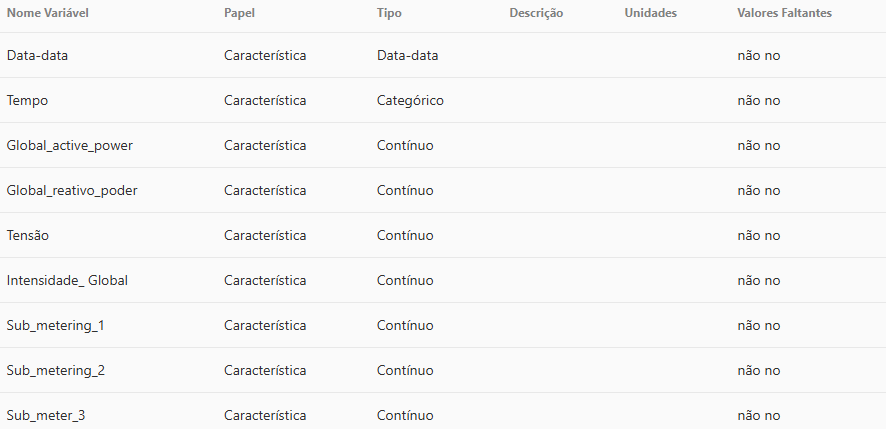

* **date**: A data da medição (dia/mês/ano)
* **time**: O horário da medição (hora/minuto/segundo)
* **global_active_power**: Potência ativa média da casa em quilowatts
* **global_reactive_power**: Potência reativa média da casa em quilowatts
* **voltage**: A tensão elétrica média em volts
* **global_intensity**: A intensidade de corrente média em ampères
* **sub_metering_1**: Consumo de energia da cozinha (principalmente máquina de lavar louça, forno e micro-ondas)
* **sub_metering_2**: Consumo de energia da lavanderia (máquina de lavar, secadora, geladeira e luz)
* **sub_metering_3**: Consumo de energia de aquecedor de água e ar-condicionado

In [14]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# fetch dataset
individual_household_electric_power_consumption = fetch_ucirepo(id=235)

# Data (pandas dataframes)
X = individual_household_electric_power_consumption.data.features
y = individual_household_electric_power_consumption.data.targets

# Metadata
print(individual_household_electric_power_consumption.metadata)

# Informações das variaveis
print(individual_household_electric_power_consumption.variables)

/usr/local/lib/python3.12/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


{'uci_id': 235, 'name': 'Individual Household Electric Power Consumption', 'repository_url': 'https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption', 'data_url': 'https://archive.ics.uci.edu/static/public/235/data.csv', 'abstract': 'Measurements of electric power consumption in one household with a one-minute sampling rate over a period of almost 4 years. Different electrical quantities and some sub-metering values are available.', 'area': 'Physics and Chemistry', 'tasks': ['Regression', 'Clustering'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 2075259, 'num_features': 9, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2006, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C58K54', 'creators': ['Georges Hebrail', 'Alice Berard'], 'intro_paper': None, 'additional_info': {'summary': 'This archiv

In [4]:
# Combinando Date e Time e convertendo
X['datetime'] = pd.to_datetime(X['Date'] + ' ' + X['Time'], format='%d/%m/%Y %H:%M:%S')
X = X.set_index('datetime')
X = X.drop(['Date', 'Time'], axis=1)

#Convertendo as colunas para numerico e inserindo NaN para nulos e valores que não sejam numero
for col in ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']:
    X[col] = pd.to_numeric(X[col], errors='coerce')

#Substituindo valores nulos pela média dos ultimos 3 dias
X = X.fillna(X.rolling('3D').mean())

#Renomeando
X = X.rename(columns={'Sub_metering_1': 'Cozinha', 'Sub_metering_2': 'Lavanderia', 'Sub_metering_3': 'Climatizadores'})

display(X.head())

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Cozinha,Lavanderia,Climatizadores
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
# Calculando a média das medições e add em novas colunas
X['Cozinha_media_dia'] = X['Cozinha'].resample('D').mean().reindex(X.index, method='nearest')
X['Lavanderia_media_dia'] = X['Lavanderia'].resample('D').mean().reindex(X.index, method='nearest')
X['Climatizadores_media_dia'] = X['Climatizadores'].resample('D').mean().reindex(X.index, method='nearest')

display(X.head())

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Cozinha,Lavanderia,Climatizadores,Cozinha_media_dia,Lavanderia_media_dia,Climatizadores_media_dia
datetime,,,,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,1.411806,2.907639,9.264583
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,1.411806,2.907639,9.264583
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,1.411806,2.907639,9.264583
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,1.411806,2.907639,9.264583
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,1.411806,2.907639,9.264583


# Objetivo
Analise o dataframe para identificar relações potenciais e prepará-lo para regressão linear para prever o consumo de energia.

uso de (`info()`) para extrair as informações e a descrição (`describe()`) do dataframe para entender os tipos de dados, contagens de não nulos e estatísticas básicas.



In [6]:
X.info()
display(X.describe())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 10 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   Global_active_power       float64
 1   Global_reactive_power     float64
 2   Voltage                   float64
 3   Global_intensity          float64
 4   Cozinha                   float64
 5   Lavanderia                float64
 6   Climatizadores            float64
 7   Cozinha_media_dia         float64
 8   Lavanderia_media_dia      float64
 9   Climatizadores_media_dia  float64
dtypes: float64(10)
memory usage: 174.2 MB


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Cozinha,Lavanderia,Climatizadores,Cozinha_media_dia,Lavanderia_media_dia,Climatizadores_media_dia
count,2.071434e+06,2.071434e+06,2.071434e+06,2.071434e+06,2.071434e+06,2.071434e+06,2.071434e+06,2.073819e+06,2.073819e+06,2.073819e+06
mean,1.090094e+00,1.237221e-01,2.408369e+02,4.621416e+00,1.119291e+00,1.293902e+00,6.451722e+00,1.118925e+00,1.292258e+00,6.445927e+00
std,1.052027e+00,1.121365e-01,3.236055e+00,4.422111e+00,6.120279e+00,5.791286e+00,8.394728e+00,1.098521e+00,1.447748e+00,2.551263e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.944444e-01
25%,3.100000e-01,4.800000e-02,2.390000e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.847222e-01,3.013889e-01,4.641921e+00
50%,6.240000e-01,1.020000e-01,2.410100e+02,2.800000e+00,0.000000e+00,0.000000e+00,1.000000e+00,7.784722e-01,4.840278e-01,6.447917e+00
75%,1.522000e+00,1.940000e-01,2.428700e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01,1.532639e+00,1.884766e+00,8.144444e+00
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01,7.763935e+00,8.409028e+00,1.648819e+01


## Entender os dados




Criação de histogramas e box plots para as colunas numéricas em X para visualizar suas distribuições e possíveis valores atípicos.



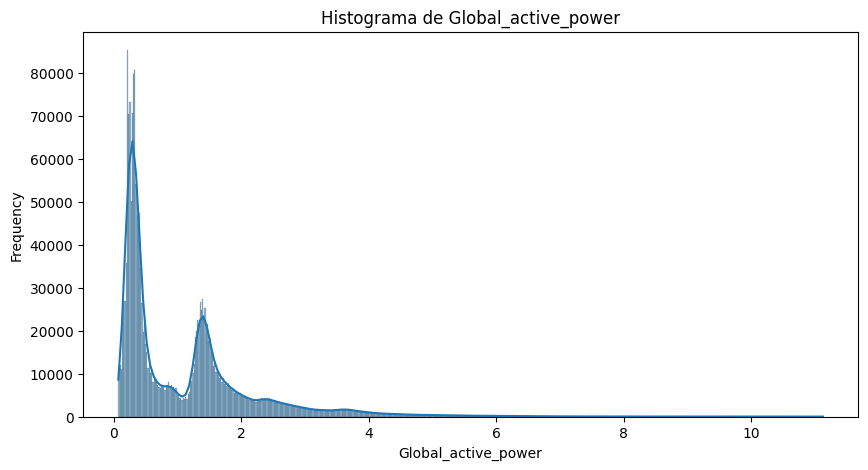

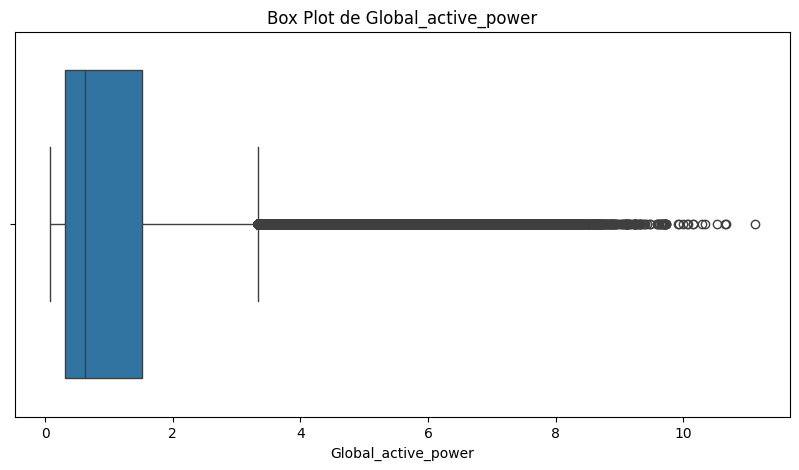

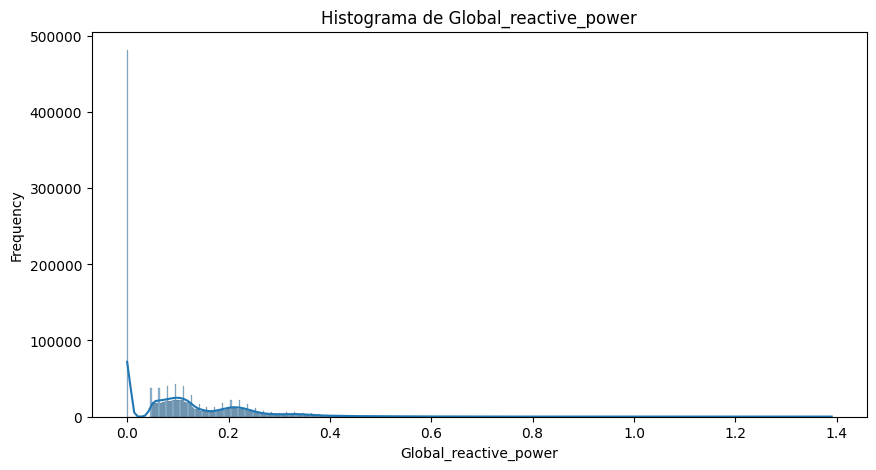

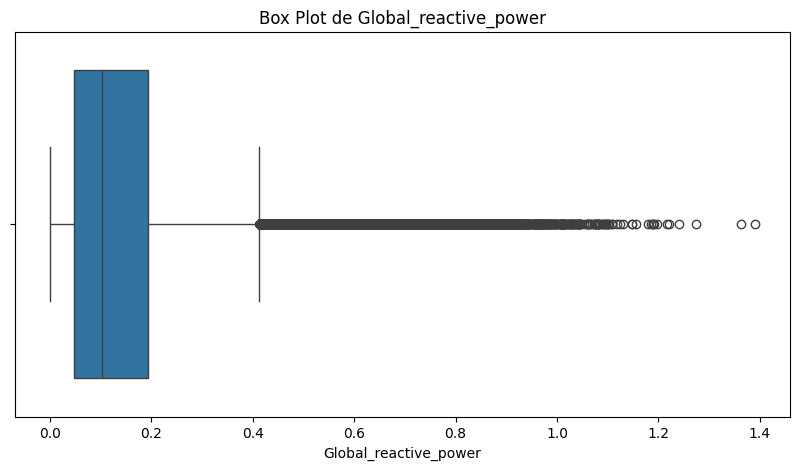

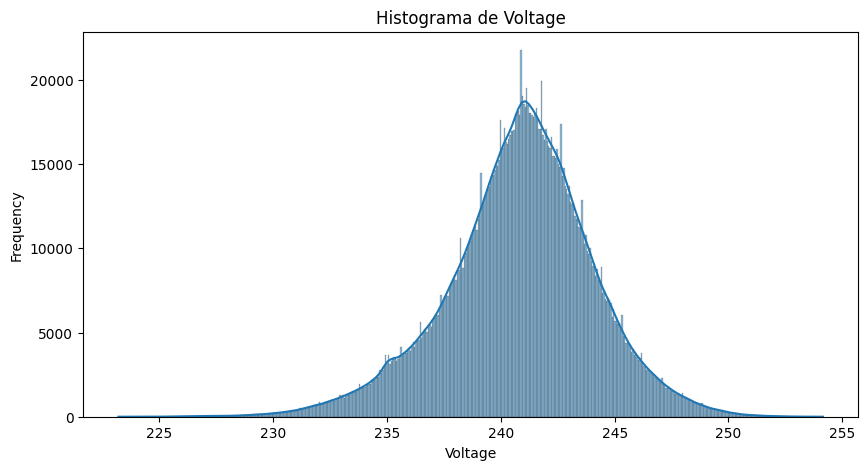

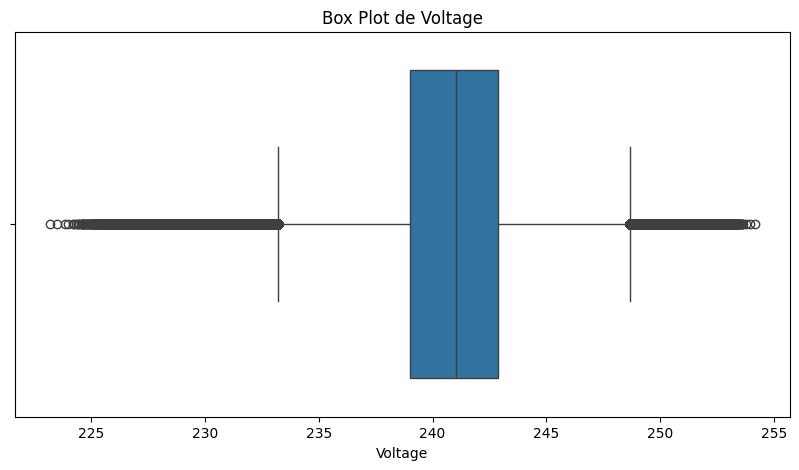

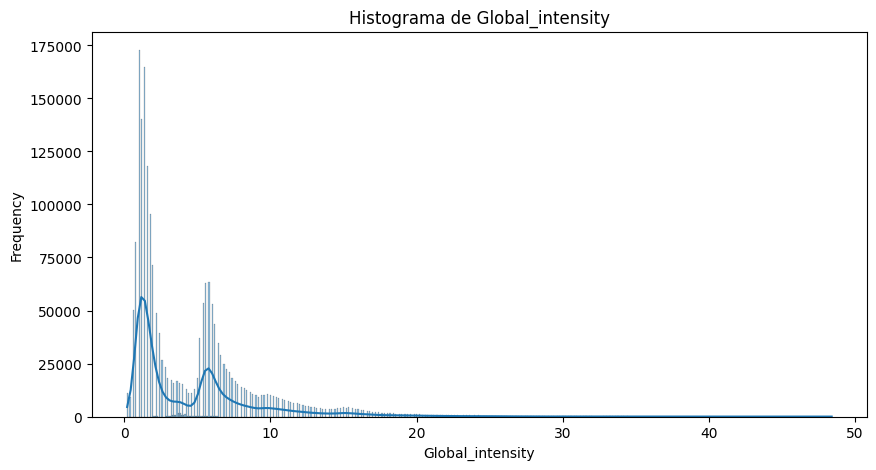

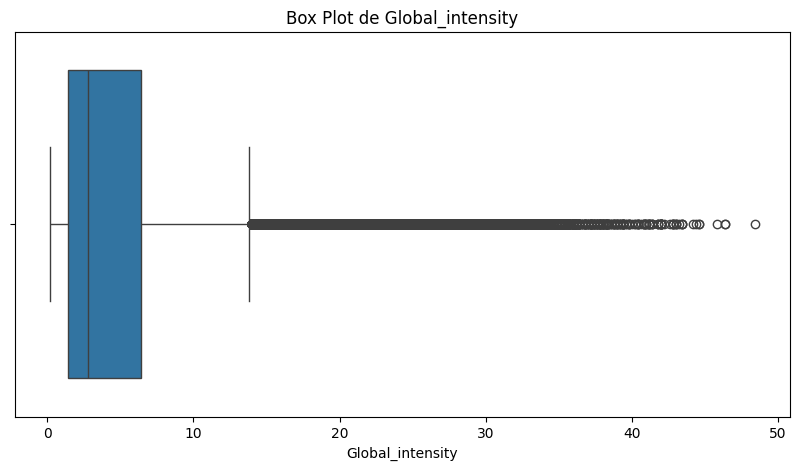

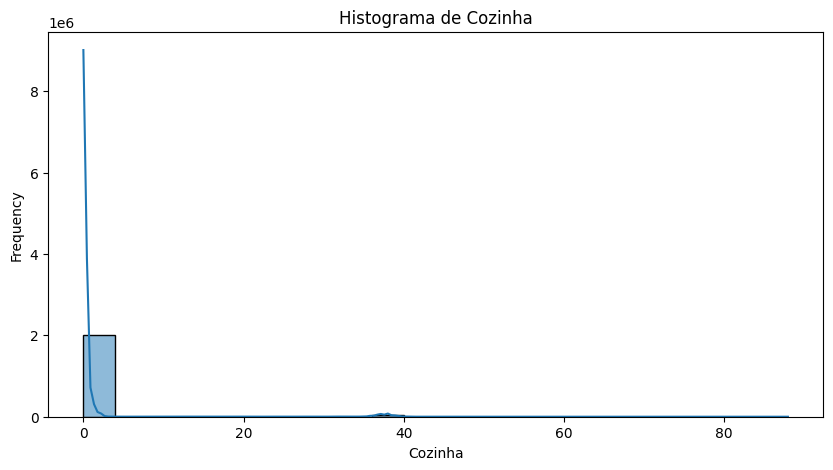

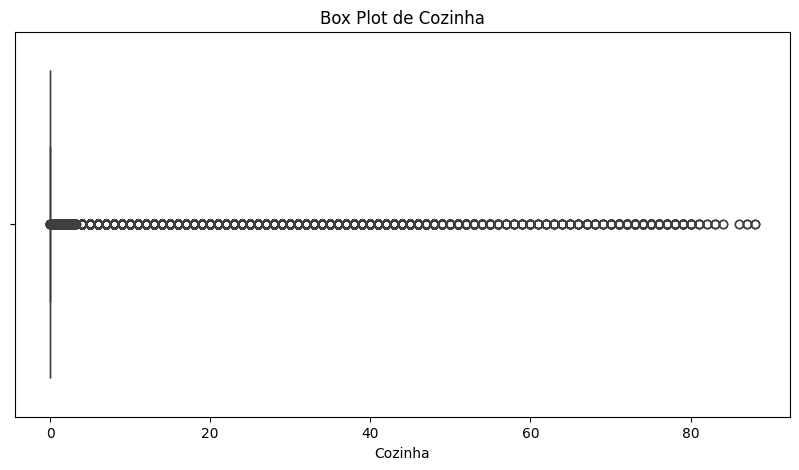

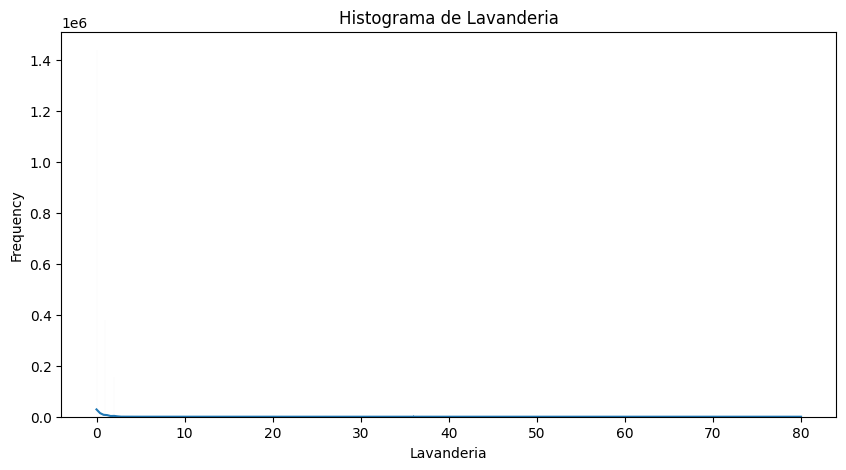

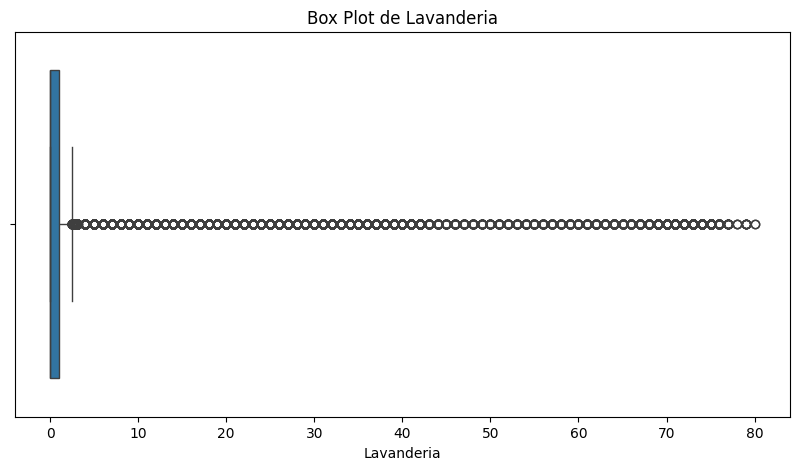

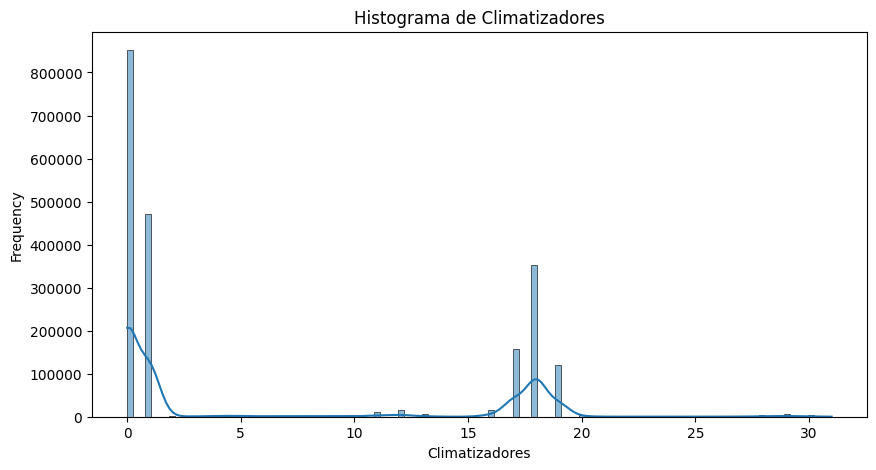

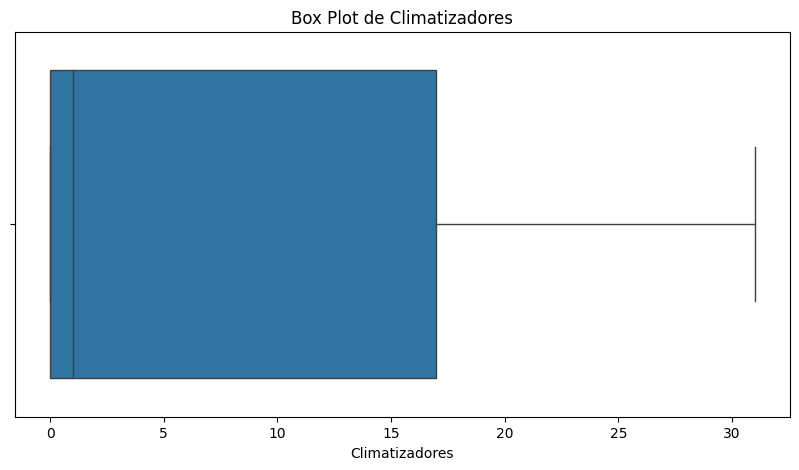

In [7]:
numerical_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Cozinha', 'Lavanderia', 'Climatizadores']

for col in numerical_cols:
    plt.figure(figsize=(10, 5))
    sns.histplot(X[col].dropna(), kde=True)
    plt.title(f'Histograma de {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

    plt.figure(figsize=(10, 5))
    sns.boxplot(x=X[col].dropna())
    plt.title(f'Box Plot de {col}')
    plt.xlabel(col)
    plt.show()

## Identificar relações potenciais

Explorando as correlações e relações entre a 'Global_active_power' (ou outras métricas de energia relevantes) e outras características como hora do dia, dia da semana ou os valores de sub-medição.



Calculando e visualizando a matriz de correlação para as colunas numéricas relevantes, em seguida, extraindo características baseadas no tempo e visualizando suas relações com 'Global_active_power'. Finalmente, visualizando a relação entre 'Global_active_power' e as variáveis de sub-medição.



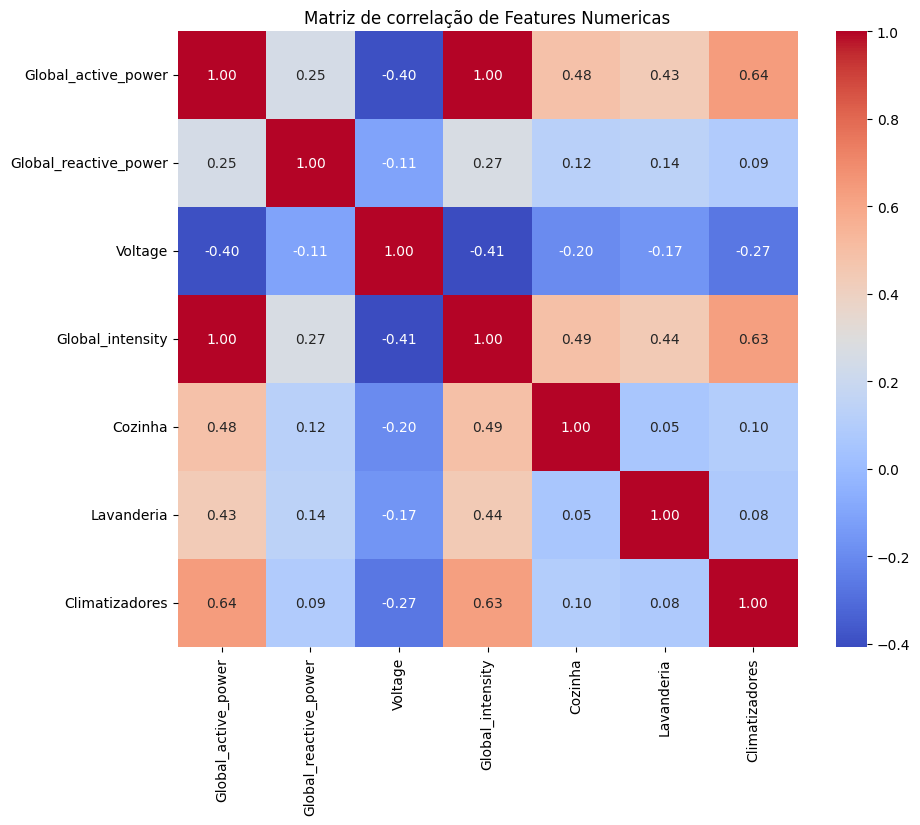

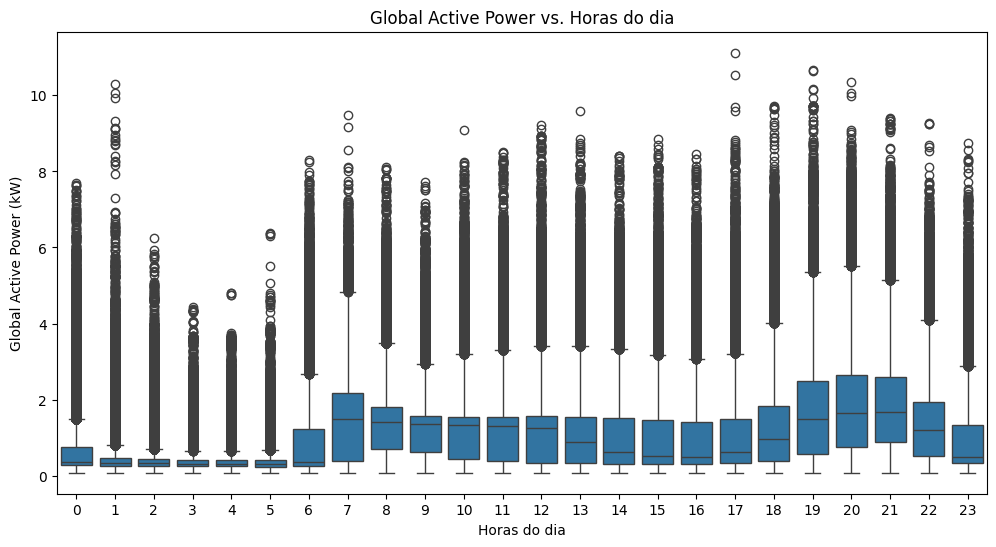

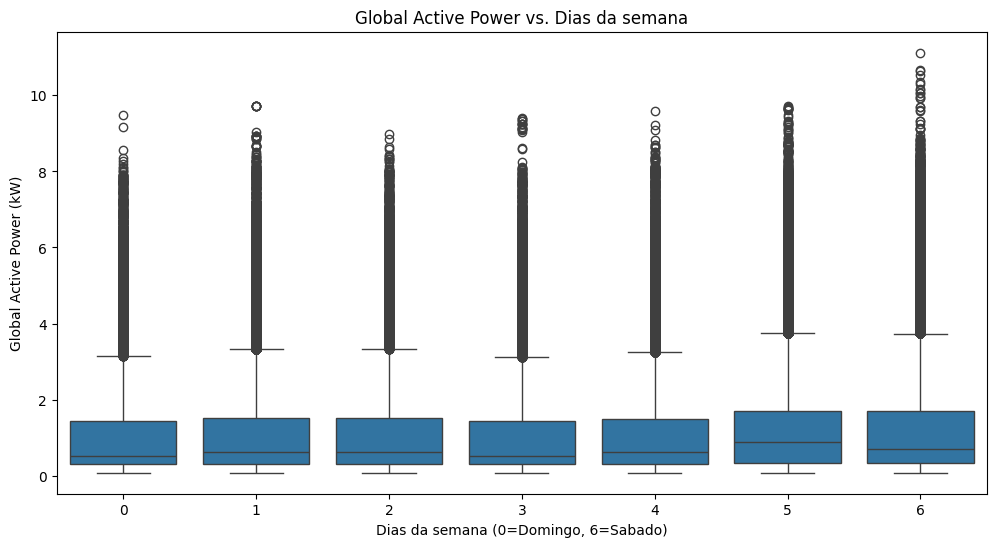

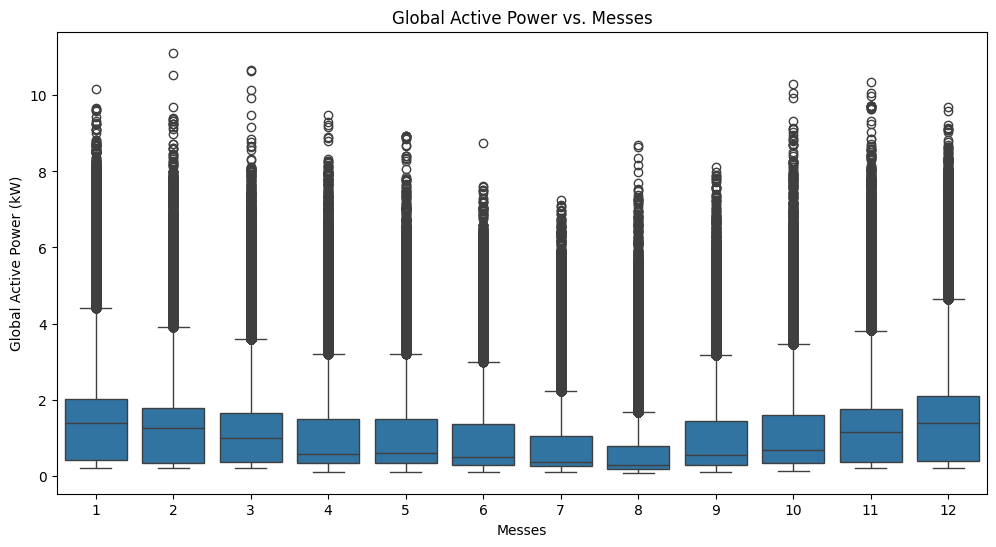

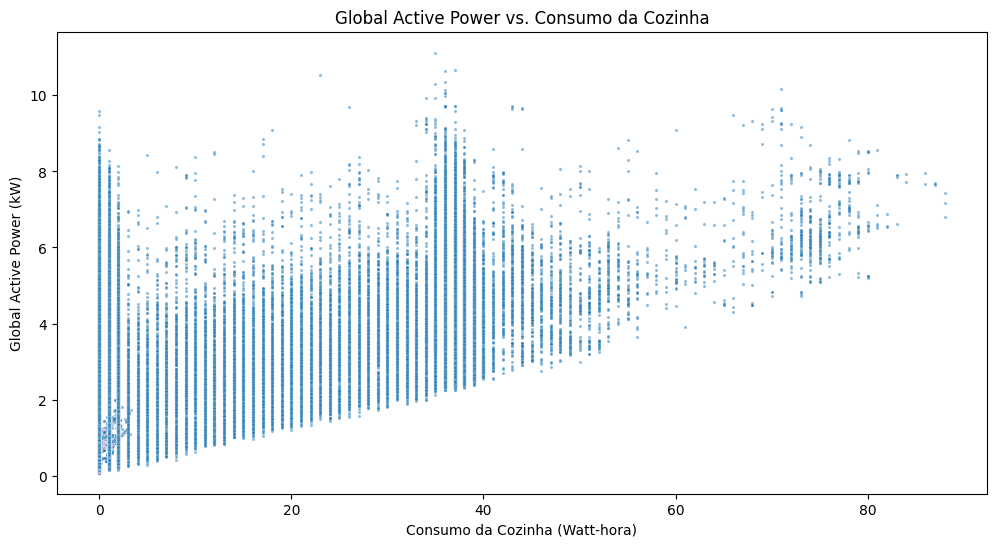

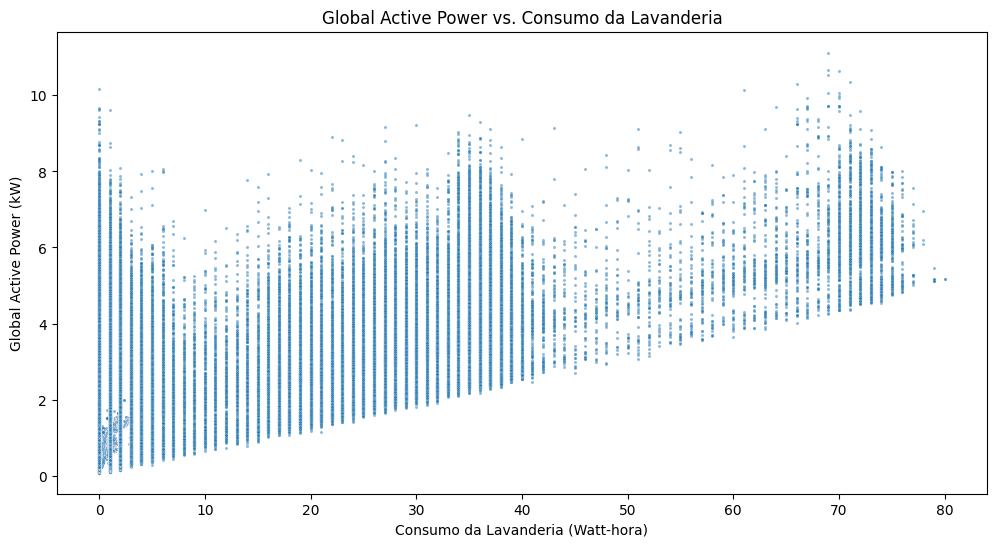

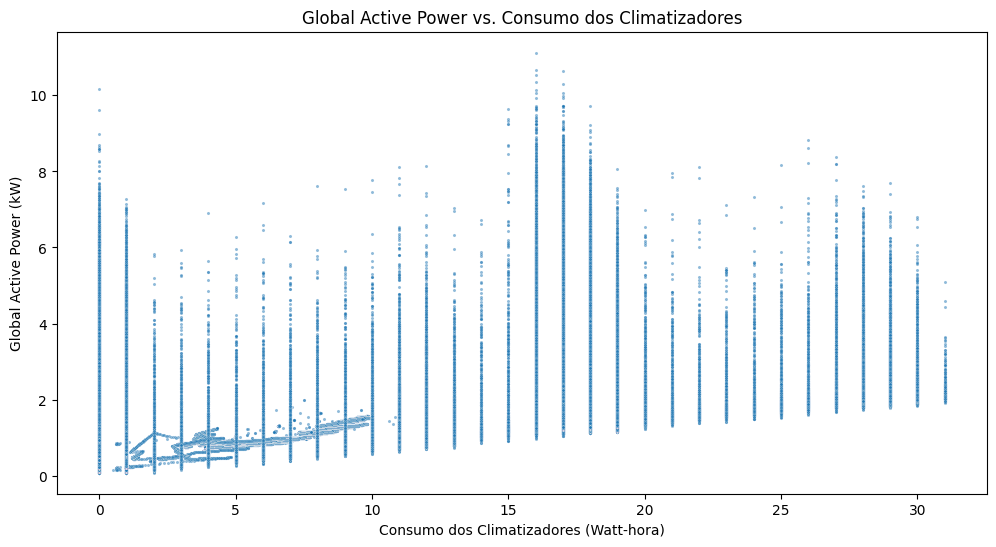

In [8]:
# Calculando a matrix de correlação
numerical_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Cozinha', 'Lavanderia', 'Climatizadores']
correlation_matrix = X[numerical_cols].corr()

# Visualizando a correlação usando heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de correlação de Features Numericas')
plt.show()

# Extraindo as features de data
X['hour'] = X.index.hour
X['day_of_week'] = X.index.dayofweek
X['month'] = X.index.month

# Analisando a correlação de 'Global_active_power' e data features
plt.figure(figsize=(12, 6))
sns.boxplot(x='hour', y='Global_active_power', data=X)
plt.title('Global Active Power vs. Horas do dia')
plt.xlabel('Horas do dia')
plt.ylabel('Global Active Power (kW)')
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(x='day_of_week', y='Global_active_power', data=X)
plt.title('Global Active Power vs. Dias da semana')
plt.xlabel('Dias da semana (0=Domingo, 6=Sabado)')
plt.ylabel('Global Active Power (kW)')
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(x='month', y='Global_active_power', data=X)
plt.title('Global Active Power vs. Messes')
plt.xlabel('Messes')
plt.ylabel('Global Active Power (kW)')
plt.show()

# Examinando a relação de 'Global_active_power' e variaveis sub-metering
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Cozinha', y='Global_active_power', data=X, alpha=0.5, s=5)
plt.title('Global Active Power vs. Consumo da Cozinha')
plt.xlabel('Consumo da Cozinha (Watt-hora)')
plt.ylabel('Global Active Power (kW)')
plt.show()

plt.figure(figsize=(12, 6))
sns.scatterplot(x='Lavanderia', y='Global_active_power', data=X, alpha=0.5, s=5)
plt.title('Global Active Power vs. Consumo da Lavanderia')
plt.xlabel('Consumo da Lavanderia (Watt-hora)')
plt.ylabel('Global Active Power (kW)')
plt.show()

plt.figure(figsize=(12, 6))
sns.scatterplot(x='Climatizadores', y='Global_active_power', data=X, alpha=0.5, s=5)
plt.title('Global Active Power vs. Consumo dos Climatizadores')
plt.xlabel('Consumo dos Climatizadores (Watt-hora)')
plt.ylabel('Global Active Power (kW)')
plt.show()

## Engenharia de características

Criando novas características que possam ser relevantes para prever o consumo de energia, como hora do dia, dia da semana ou até mesmo indicadores sazonais.



Extraindo a hora do dia, dia da semana e mês do índice de datetime e adicione-os como novas colunas ao DataFrame X.



In [9]:
X['hour'] = X.index.hour
X['day_of_week'] = X.index.dayofweek
X['month'] = X.index.month

display(X.head())

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Cozinha,Lavanderia,Climatizadores,Cozinha_media_dia,Lavanderia_media_dia,Climatizadores_media_dia,hour,day_of_week,month
datetime,,,,,,,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,1.411806,2.907639,9.264583,17,5,12
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,1.411806,2.907639,9.264583,17,5,12
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,1.411806,2.907639,9.264583,17,5,12
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,1.411806,2.907639,9.264583,17,5,12
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,1.411806,2.907639,9.264583,17,5,12


## Preparação de dados para regressão

Tratando quaisquer valores ausentes restantes e considerabdo escalar ou transformar características, se necessário, para o modelo de regressão linear.



Verificando se há quaisquer valores ausentes restantes no DataFrame X.



In [10]:
print(X.isnull().sum())

Global_active_power         3825
Global_reactive_power       3825
Voltage                     3825
Global_intensity            3825
Cozinha                     3825
Lavanderia                  3825
Climatizadores              3825
Cozinha_media_dia           1440
Lavanderia_media_dia        1440
Climatizadores_media_dia    1440
hour                           0
day_of_week                    0
month                          0
dtype: int64


Imputando os valores ausentes restantes usando a média das respectivas colunas e, em seguida, selecionando as características e a variável alvo para regressão linear.



In [11]:
for col in ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Cozinha', 'Lavanderia', 'Climatizadores', 'Cozinha_media_dia', 'Lavanderia_media_dia', 'Climatizadores_media_dia']:
    X[col] = X[col].fillna(X[col].mean())

y = X['Global_active_power']
X = X.drop('Global_active_power', axis=1)

print(X.isnull().sum())

Global_reactive_power       0
Voltage                     0
Global_intensity            0
Cozinha                     0
Lavanderia                  0
Climatizadores              0
Cozinha_media_dia           0
Lavanderia_media_dia        0
Climatizadores_media_dia    0
hour                        0
day_of_week                 0
month                       0
dtype: int64


In [12]:
#Quebrando os dados para treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Iniciando e treinando o modelo no metodo fit
model = LinearRegression()
model.fit(X_train, y_train)

#Realizando predições
y_pred = model.predict(X_test)

#Puxando medidores do modelo
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'R-squared (R2): {r2}')

Mean Squared Error (MSE): 0.0016237246393403708
Root Mean Squared Error (RMSE): 0.040295466734365674
R-squared (R2): 0.9985309047248992


Com os resultados fornecidos, temos um MSE próximo de 0.04 o que indica uma previsão muit próxima da realidade. Assim, ao obtermos um valor de R2 de 0,9985 ou seja 99,85% indica que o modelo se ajusta aos dados de forma exelente.